In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error


In [ ]:

X, y = make_regression(n_samples=1000, n_features=5, noise=10, random_state=42)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(5,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

In [ ]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])


In [ ]:

history = model.fit(
    X_train, y_train,
    epochs=30, batch_size=32,
    validation_split=0.2, verbose=1
)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 4171.0415 - mae: 50.9290 - val_loss: 4886.0015 - val_mae: 54.9220
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4093.0156 - mae: 50.4450 - val_loss: 4784.3179 - val_mae: 54.3170
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3973.6440 - mae: 49.6776 - val_loss: 4612.2163 - val_mae: 53.2733
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3772.5688 - mae: 48.3512 - val_loss: 4325.2339 - val_mae: 51.4778
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3453.5493 - mae: 46.1020 - val_loss: 3897.0769 - val_mae: 48.6536
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3005.8389 - mae: 42.7611 - val_loss: 3326.9180 - val_mae: 44.5820
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2443.3967 - mae: 38.2446 - val_loss: 2645.0796 - val_mae: 39.3359
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 1832.9047 - mae: 32.4249 - val_loss: 1940.0609 - val_mae: 33.2665
Epoc

In [ ]:

loss, mae = model.evaluate(X_test, y_test, verbose=0)
y_pred = model.predict(X_test, verbose=0)

print("Test MSE:", mean_squared_error(y_test, y_pred))
print("Test MAE:", mae)

Test MSE: 131.13291926451683
Test MAE: 9.219091415405273


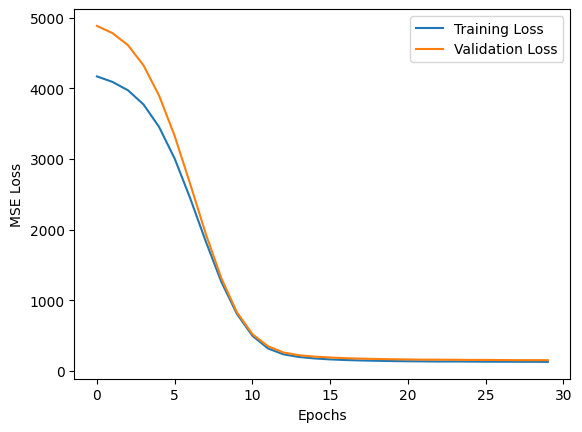

In [ ]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

In [ ]:

result = pd.DataFrame({
    'Actual': y_test[:10],
    'Predicted': y_pred.flatten()[:10]
})
print(result)


       Actual   Predicted
0  -49.539260  -61.978554
1  -58.226259  -68.227486
2   47.171144   51.877304
3   -4.063442  -16.212599
4   56.864649   67.094284
5   47.238623   33.622959
6  -22.577271  -29.213179
7  -70.931677  -55.350334
8   58.041742   58.714275
9 -115.877071 -124.056931
